<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [11]:
#Importar Librerias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.formula.api import ols

In [12]:
# 1. Carga de datos
# 1. Carga del conjunto de datos
df = pd.read_csv('college.csv', usecols=['salary', 'cost', 'location'])

# Conversión a categórica
df['location'] = df['location'].astype('category')

# 2. Estadística descriptiva
print('--- Estadística Descriptiva (salary y cost) ---')
print(df[['salary', 'cost']].describe())

# 3. Conteo por categoría en location
print('\n--- Conteos por Localidad ---')
print(df['location'].value_counts())

# 4. One-Hot Encoding con K-1 (drop_first=True)
df_encoded = pd.get_dummies(
    df, columns=['location'], drop_first=True, dtype=float
)

print('\n--- Dataset Codificado (Primeras 5 filas) ---')
print(df_encoded.head())

--- Estadística Descriptiva (salary y cost) ---
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000

--- Conteos por Localidad ---
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64

--- Dataset Codificado (Primeras 5 filas) ---
   salary    cost  location_NE  location_S  location_W
0  119000  189300          1.0         0.0         0.0
1  121000  189600          1.0         0.0         0.0
2  123000  188400          1.0         0.0         0.0
3  123000  188700          1.0         0.0         0.0
4  110000  194200          1.0         0.0         0.0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




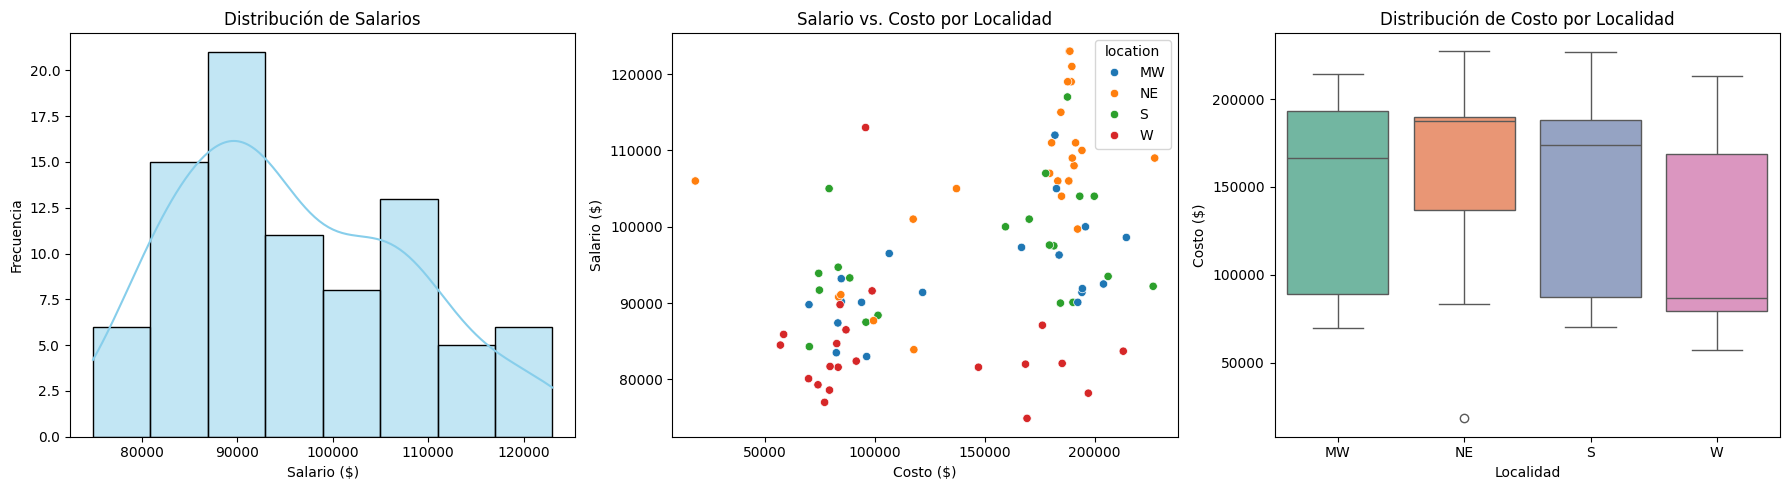

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma de salary
sns.histplot(df['salary'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Salarios')
axes[0].set_xlabel('Salario ($)')
axes[0].set_ylabel('Frecuencia')

# 2. Scatter Plot: salary vs cost por location (4 colores)
sns.scatterplot(
    data=df, x='cost', y='salary', hue='location', palette='tab10', ax=axes[1]
)
axes[1].set_title('Salario vs. Costo por Localidad')
axes[1].set_xlabel('Costo ($)')
axes[1].set_ylabel('Salario ($)')

# 3. Boxplot: cost por location
sns.boxplot(data=df, x='location', y='cost', palette='Set2', ax=axes[2], hue='location')
axes[2].set_title('Distribución de Costo por Localidad')
axes[2].set_xlabel('Localidad')
axes[2].set_ylabel('Costo ($)')

plt.tight_layout()
plt.show()

**Observaciones:**

- **Histograma de Salarios**: Lo que muestra es que los salarios van desde aproximadamente 75,000 hasta 123,000, el pico maximo se encuentra entre 87,000 y 93,000.

- **Salario vs. Costo por Localidad**:
  - La región NE (Noreste - Naranja) domina la parte superior derecha de la gráfica concentrando los salarios más altos (superiores a 105,000 e incluso 120,000) y los costos de educación más elevados (mayores a 180,000).
  - Las regiones MW (Midwest - Azul) y S (Sur - Verde) se ubican en niveles de salario medio-alto
  - La región W (Oeste - Rojo) destaca por tener, a costos educativos similares o altos, salarios más bajos en comparación con el Noreste.

- **Distribución de Costo por Localidad**:
  - MW (Midwest): Presenta una mediana alta (alrededor de 165,000) con gran dispersión entre 70,000 y 215,000.
  - NE (Noreste): Muestra la mediana de costo más alta (cerca de 188,000) y la mayor concentración en costos elevados, además de presentar un valor atípico (outlier) por debajo de los 20,000.
  - S (Sur): Tiene una dispersión muy amplia de costos similares al Midwest.
  - W (Oeste): Presenta la mediana de costo más baja (alrededor de 87,000) y una distribución sesgada hacia costos menores en comparación con las otras tres regiones.  


# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [14]:
# Variables independientes (X) y dependiente (y)
# Definición de variables
X = df_encoded.drop(columns=['salary'])
y = df_encoded['salary']

# Ajuste del modelo de regresión
modelo = LinearRegression()
modelo.fit(X, y)

# Impresión de coeficientes
beta_0 = modelo.intercept_
coefs = dict(zip(X.columns, modelo.coef_))

print('COEFICIENTES DEL MODELO')
print(f'Intercepto (Beta_0)   : {beta_0:,.2f}')
for col, val in coefs.items():
  print(f'Coeficiente {col:<12}: {val:,.4f}')

print('\nECUACIÓN DE REGRESIÓN')
print(
    f'Salario = {beta_0:,.2f} + ({coefs["cost"]:.4f} * Costo)'
    f' + ({coefs["location_NE"]:.2f} * location_NE)'
    f' + ({coefs["location_S"]:.2f} * location_S)'
    f' + ({coefs["location_W"]:.2f} * location_W)'
)

# Sustitución de Ejemplo para Interpretación Práctica
# Ejemplo: Evaluar una universidad con un Costo = $150,000 en diferentes regiones
costo_ejemplo = 150000

print(
    f'\nEJEMPLO DE SUSTITUCIÓN PRÁCTICA (Para un Costo de'
    f' ${costo_ejemplo:,.2f})'
)

# a) Midwest (MW): location_NE=0, location_S=0, location_W=0
pred_mw = beta_0 + coefs['cost'] * costo_ejemplo
print(f'• Midwest (MW) [0, 0, 0] : ${pred_mw:,.2f}')

# b) Noreste (NE): location_NE=1, location_S=0, location_W=0
pred_ne = beta_0 + coefs['cost'] * costo_ejemplo + coefs['location_NE']
print(f'• Noreste (NE) [1, 0, 0] : ${pred_ne:,.2f}')

# c) Sur (S): location_NE=0, location_S=1, location_W=0
pred_s = beta_0 + coefs['cost'] * costo_ejemplo + coefs['location_S']
print(f'• Sur (S)     [0, 1, 0] : ${pred_s:,.2f}')

# d) Oeste (W): location_NE=0, location_S=0, location_W=1
pred_w = beta_0 + coefs['cost'] * costo_ejemplo + coefs['location_W']
print(f'• Oeste (W)   [0, 0, 1] : ${pred_w:,.2f}')

COEFICIENTES DEL MODELO
Intercepto (Beta_0)   : 84,988.72
Coeficiente cost        : 0.0605
Coeficiente location_NE : 12,032.8197
Coeficiente location_S  : 2,800.3450
Coeficiente location_W  : -7,721.4201

ECUACIÓN DE REGRESIÓN
Salario = 84,988.72 + (0.0605 * Costo) + (12032.82 * location_NE) + (2800.35 * location_S) + (-7721.42 * location_W)

EJEMPLO DE SUSTITUCIÓN PRÁCTICA (Para un Costo de $150,000.00)
• Midwest (MW) [0, 0, 0] : $94,066.35
• Noreste (NE) [1, 0, 0] : $106,099.17
• Sur (S)     [0, 1, 0] : $96,866.69
• Oeste (W)   [0, 0, 1] : $86,344.93


# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

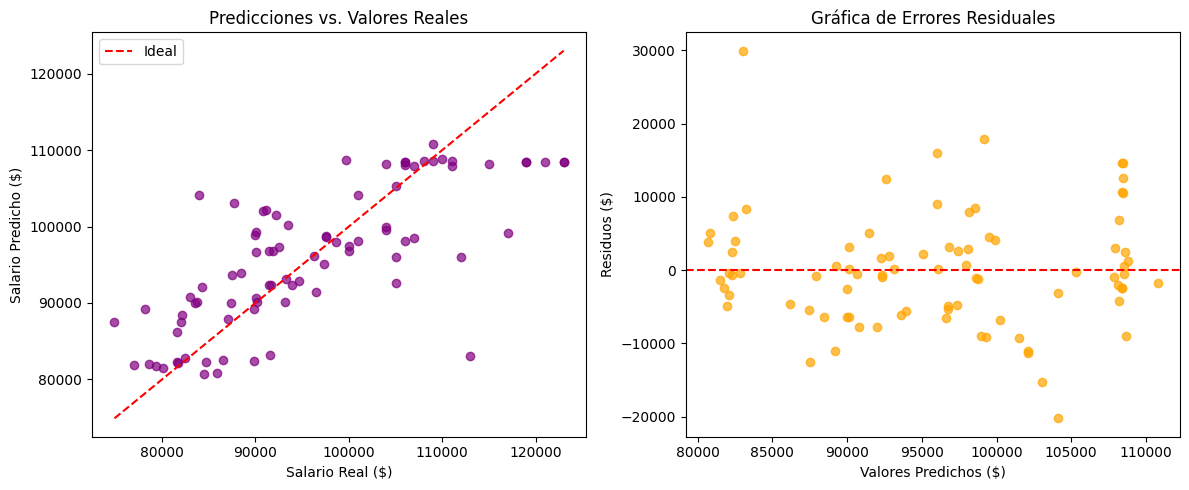

In [15]:
y_pred = modelo.predict(X)
residuals = y - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Real vs Predicho
axes[0].scatter(y, y_pred, alpha=0.7, color='purple')
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Ideal')
axes[0].set_xlabel('Salario Real ($)')
axes[0].set_ylabel('Salario Predicho ($)')
axes[0].set_title('Predicciones vs. Valores Reales')
axes[0].legend()

# Residuos
axes[1].scatter(y_pred, residuals, alpha=0.7, color='orange')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Valores Predichos ($)')
axes[1].set_ylabel('Residuos ($)')
axes[1].set_title('Gráfica de Errores Residuales')

plt.tight_layout()
plt.show()

**Observaciones**

El modelo de regresión lineal múltiple con variables dummy es válido y cumple con los supuestos de linealidad y varianza del error. Pero, presenta cierta rigidez estructural en los extremos: tiende a fijar un "techo" alrededor de $108,000 para los salarios más elevados ademas de inflar levemente los salarios más bajos.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [16]:
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mse)

print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R^2 Score: {r2:.4f}')

MSE: 60480269.15
RMSE: 7776.91
R^2 Score: 0.5705


**Resultados:**

- $R^2$: El valor obtenido demuestra que el costo de la educación y la localización geográfica explican una proporción considerable de las diferencias en los salarios de egreso de los graduados.
- MSE y RMSE: El valor del MSE refleja la variabilidad del error residual en dólares al cuadrado. Al tomar su raíz, obtenemos la desviación promedio del modelo en dólares reales.

Desde el punto de vista práctico, el modelo demuestra que evaluar el retorno de inversión educativo considerando únicamente la colegiatura es insuficiente. La combinación de costo + ubicación regional proporciona un marco confiable para estimar expectativas salariales iniciales, confirmando que el Noreste necesita un margen considerablemente mayor contra el resto de las regiones.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [17]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Ajuste con fórmula de statsmodels
modelo_sm = ols('salary ~ cost + C(location)', data=df).fit()

# Tabla ANOVA Tipo II
tabla_anova = sm.stats.anova_lm(modelo_sm, typ=2)

print('Tabla ANOVA (Statsmodels)')
print(tabla_anova)

Tabla ANOVA (Statsmodels)
                   sum_sq    df          F        PR(>F)
C(location)  4.071774e+09   3.0  21.121259  3.570975e-10
cost         7.878166e+08   1.0  12.259774  7.600629e-04
Residual     5.140823e+09  80.0        NaN           NaN
